# P2.9 · Metrics by hand

**ID:** P2.9 · **Target:** 15 min · **Plan week:** 2 (and again in 5) · **Part:** P

**The drill.** Implement the evaluation metrics you quote in every paper and interview, from tensors, and check
each against scikit-learn. Guide §P2 "Must include": accuracy, top-k, precision/recall/F1 (micro/macro),
ROC-AUC via ranking, calibration (ECE). Also here: confusion matrix, weighted/binary averaging and
zero-division handling, average precision (PR-AUC), reliability diagram, Brier score.

**Allowed:** torch tensor ops (`argmax`, `topk`, `bincount`, `sort`, `unique`, `cumsum`, indexing).
**Not allowed inside your functions:** `sklearn.metrics`, `torchmetrics`, `scipy.stats.rankdata`. The tests use
scikit-learn as the reference. The scores come from a small MLP trained (deliberately without regularization, on
partly noisy labels) on scikit-learn's bundled 8×8 digits, so they look like real model outputs, overconfidence included.

**Fill in** every `raise NotImplementedError`; run the test cell under each function.

## Sources
- scikit-learn metric docs (reference semantics, including `zero_division` and averaging):
  user guide https://scikit-learn.org/stable/modules/model_evaluation.html ·
  `precision_recall_fscore_support` https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html ·
  `roc_auc_score` https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html ·
  `average_precision_score` https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html ·
  `calibration_curve` https://scikit-learn.org/stable/modules/generated/sklearn.calibration.calibration_curve.html ·
  `brier_score_loss` https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html
- T. Fawcett, *An introduction to ROC analysis*, Pattern Recognition Letters 27(8), 2006,
  DOI 10.1016/j.patrec.2005.10.010 — https://doi.org/10.1016/j.patrec.2005.10.010 (AUC = probability that a random
  positive is ranked above a random negative; equivalence to the Wilcoxon/Mann–Whitney statistic).
- J. A. Hanley, B. J. McNeil, *The meaning and use of the area under a ROC curve*, Radiology 143(1), 1982,
  DOI 10.1148/radiology.143.1.7063747 — https://doi.org/10.1148/radiology.143.1.7063747
- M. P. Naeini, G. F. Cooper, M. Hauskrecht, *Obtaining Well Calibrated Probabilities Using Bayesian Binning*,
  AAAI 2015, DOI 10.1609/aaai.v29i1.9602 — https://doi.org/10.1609/aaai.v29i1.9602 (defines ECE and MCE).
- C. Guo, G. Pleiss, Y. Sun, K. Q. Weinberger, *On Calibration of Modern Neural Networks*, ICML 2017,
  arXiv:1706.04599 — https://arxiv.org/abs/1706.04599 (equal-width-bin ECE over top-label confidence, reliability
  diagrams, temperature scaling; modern nets are overconfident).
- G. W. Brier, *Verification of forecasts expressed in terms of probability*, Monthly Weather Review 78(1), 1950,
  DOI 10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2 — https://doi.org/10.1175/1520-0493(1950)078%3C0001:VOFEIT%3E2.0.CO;2

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sklearn.metrics as skm
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.calibration import calibration_curve
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

from prep import Session, check, check_close, seed_everything

s = Session("P2.9", target_min=15)
seed_everything(0)

# Real-looking scores: an unregularized MLP on 8x8 digits that memorizes 30% noisy training labels
# (train accuracy -> 100%), so on clean validation data it is wrong more often than its confidence says.
X, y = load_digits(return_X_y=True)
Xtr, Xva, ytr, yva = train_test_split(X / 16.0, y, test_size=0.45, stratify=y, random_state=0)
Xtr, Xva = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(Xva, dtype=torch.float32)
ytr, y_true = torch.tensor(ytr), torch.tensor(yva)
flip = torch.rand(len(ytr)) < 0.3
ytr = torch.where(flip, torch.randint(0, 10, ytr.shape), ytr)
net = nn.Sequential(nn.Linear(64, 512), nn.ReLU(), nn.Linear(512, 10))
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
for _ in range(1500):
    opt.zero_grad(); F.cross_entropy(net(Xtr), ytr).backward(); opt.step()
with torch.no_grad():
    logits = net(Xva)
probs = logits.softmax(1)
y_pred = logits.argmax(1)
C = 10
print("val examples", len(y_true), "| classes", C)

[P2.9] started 16:44; target 15 min


val examples 809 | classes 10


## 1. Accuracy and top-k accuracy
Top-k: the true class is among the k highest scores. Aggregate over the whole set (sum of correct / N), never
an average of per-batch accuracies when the last batch is smaller.

In [2]:
def accuracy(y_pred, y_true):
    return (y_pred == y_true).float().mean().item()


def topk_accuracy(scores, y_true, k):
    """scores: (N, C). Returns a python float."""
    topk = scores.topk(k, dim=1).indices                      # (N, k)
    return (topk == y_true[:, None]).any(dim=1).float().mean().item()


check_close("accuracy", accuracy(y_pred, y_true), skm.accuracy_score(y_true, y_pred))
for k in (1, 2, 5):
    check_close(f"top-{k} accuracy", topk_accuracy(logits, y_true, k),
                skm.top_k_accuracy_score(y_true, logits.numpy(), k=k, labels=range(C)))
per_batch = np.mean([accuracy(y_pred[i:i + 64], y_true[i:i + 64]) for i in range(0, len(y_true), 64)])
print(f"mean of per-batch accuracies {per_batch:.4f} vs whole-set accuracy {accuracy(y_pred, y_true):.4f}")

ok  accuracy
ok  top-1 accuracy
ok  top-2 accuracy
ok  top-5 accuracy
mean of per-batch accuracies 0.7752 vs whole-set accuracy 0.7750


## 2. Confusion matrix
`cm[i, j]` = number of examples with **true** class i predicted as j (scikit-learn's convention: rows = truth).
One line: `bincount` of `C * y_true + y_pred`.

In [3]:
def confusion_matrix(y_true, y_pred, num_classes):
    return torch.bincount(num_classes * y_true + y_pred, minlength=num_classes**2).reshape(num_classes, num_classes)


cm = confusion_matrix(y_true, y_pred, C)
check_close("confusion matrix", cm, skm.confusion_matrix(y_true, y_pred, labels=range(C)))
check("rows are the truth", torch.equal(cm.sum(1), torch.bincount(y_true, minlength=C)))
yt_small, yp_small = torch.tensor([0, 0, 1, 1, 2, 2, 3]), torch.tensor([0, 1, 1, 1, 0, 2, 2])
check_close("confusion matrix with an unseen class", confusion_matrix(yt_small, yp_small, 5),
            skm.confusion_matrix(yt_small, yp_small, labels=range(5)))

ok  confusion matrix
ok  rows are the truth
ok  confusion matrix with an unseen class


## 3. Precision, recall, F1 from the confusion matrix
Per class: $TP=\text{diag}$, $FP = \text{col sum} - TP$, $FN = \text{row sum} - TP$;
$P = TP/(TP+FP)$, $R = TP/(TP+FN)$, $F_1 = 2TP/(2TP+FP+FN)$ (= harmonic mean of P and R).
When a denominator is 0 (class never predicted, or never present), return `zero_division` instead.
Averages: **macro** = unweighted mean over classes; **weighted** = mean weighted by support (row sums);
**micro** = pool TP/FP/FN over classes first (for single-label multiclass, micro P = R = F1 = accuracy);
**binary** = the class `pos_label=1` only. Return `(precision, recall, f1)`; per-class tensors when `average=None`.

In [4]:
def precision_recall_f1(cm, average="macro", zero_division=0.0):
    cm = cm.double()
    tp = cm.diag()
    fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    if average == "micro":
        tp, fp, fn = tp.sum(), fp.sum(), fn.sum()
    if average == "binary":
        tp, fp, fn = tp[1], fp[1], fn[1]

    def div(a, b):
        return torch.where(b > 0, a / b.clamp(min=1e-300), torch.full_like(a, zero_division))

    p, r, f = div(tp, tp + fp), div(tp, tp + fn), div(2 * tp, 2 * tp + fp + fn)
    if average == "macro":
        p, r, f = p.mean(), r.mean(), f.mean()
    elif average == "weighted":
        w = cm.sum(1) / cm.sum()
        p, r, f = (p * w).sum(), (r * w).sum(), (f * w).sum()
    return p, r, f


def sk_prf(yt, yp, labels, average, zd):
    return skm.precision_recall_fscore_support(yt, yp, labels=labels, average=average, zero_division=zd)[:3]


for (yt, yp, nc) in ((y_true, y_pred, C), (yt_small, yp_small, 5)):   # second case: class 3 never predicted, class 4 absent
    for avg in ("micro", "macro", "weighted", None):
        for zd in (0.0, 1.0):
            got = precision_recall_f1(confusion_matrix(yt, yp, nc), avg, zd)
            for name, g, e in zip("PRF", got, sk_prf(yt.numpy(), yp.numpy(), list(range(nc)), avg, zd)):
                check_close(f"{name} average={avg} zero_division={zd} (C={nc})", g, e)
yb_true, yb_pred = (y_true == 3).long(), (y_pred == 3).long()
for name, g, e in zip("PRF", precision_recall_f1(confusion_matrix(yb_true, yb_pred, 2), "binary"),
                      sk_prf(yb_true.numpy(), yb_pred.numpy(), None, "binary", 0.0)):
    check_close(f"{name} binary (digit 3 vs rest)", g, e)
p_micro = precision_recall_f1(cm, "micro")[0]
check_close("micro-P == accuracy for single-label multiclass", p_micro, accuracy(y_pred, y_true))

ok  P average=micro zero_division=0.0 (C=10)
ok  R average=micro zero_division=0.0 (C=10)
ok  F average=micro zero_division=0.0 (C=10)
ok  P average=micro zero_division=1.0 (C=10)
ok  R average=micro zero_division=1.0 (C=10)
ok  F average=micro zero_division=1.0 (C=10)
ok  P average=macro zero_division=0.0 (C=10)
ok  R average=macro zero_division=0.0 (C=10)
ok  F average=macro zero_division=0.0 (C=10)
ok  P average=macro zero_division=1.0 (C=10)
ok  R average=macro zero_division=1.0 (C=10)
ok  F average=macro zero_division=1.0 (C=10)
ok  P average=weighted zero_division=0.0 (C=10)
ok  R average=weighted zero_division=0.0 (C=10)
ok  F average=weighted zero_division=0.0 (C=10)
ok  P average=weighted zero_division=1.0 (C=10)
ok  R average=weighted zero_division=1.0 (C=10)
ok  F average=weighted zero_division=1.0 (C=10)
ok  P average=None zero_division=0.0 (C=10)
ok  R average=None zero_division=0.0 (C=10)
ok  F average=None zero_division=0.0 (C=10)
ok  P average=None zero_division=1.0 (C=

## 4. ROC-AUC via ranking (Mann–Whitney U)
$\text{AUC} = P(s^+ > s^-) + \tfrac12 P(s^+ = s^-)$ over random positive/negative pairs. With ranks $1..n$ of all scores
(ties get the **average** of the ranks they span), $R_+$ = sum of positive ranks, $n_1$ positives, $n_0$ negatives:
$$\text{AUC} = \frac{R_+ - n_1(n_1+1)/2}{n_1 n_0}.$$
$O(n\log n)$, no thresholds, no curve. Hint for average ranks: `torch.unique(..., return_inverse=True, return_counts=True)`.

In [5]:
def average_ranks(x):
    """1-based ranks of a 1-D tensor; tied values get the mean of the ranks they occupy."""
    _, inverse, counts = torch.unique(x, sorted=True, return_inverse=True, return_counts=True)
    end = counts.cumsum(0).double()              # last rank occupied by each distinct value
    start = end - counts + 1
    return ((start + end) / 2)[inverse]


def roc_auc(scores, labels):
    """scores: (N,) float, labels: (N,) in {0, 1}."""
    r = average_ranks(scores)
    pos = labels == 1
    n1, n0 = pos.sum().item(), (~pos).sum().item()
    return ((r[pos].sum().item() - n1 * (n1 + 1) / 2) / (n1 * n0))


score3 = probs[:, 3]
check_close("average ranks (with ties)", average_ranks(torch.tensor([3.0, 1.0, 3.0, 2.0, 3.0])),
            torch.tensor([4.0, 1.0, 4.0, 2.0, 4.0]))
check_close("AUC digit 3 vs rest", roc_auc(score3, yb_true), skm.roc_auc_score(yb_true, score3))
torch.manual_seed(1)
tied = (torch.rand(500) * 5).floor()                       # only 5 distinct scores: ties everywhere
lab = (torch.rand(500) < 0.2 + 0.12 * tied).long()
check_close("AUC with heavy ties", roc_auc(tied, lab), skm.roc_auc_score(lab, tied))
pos_s, neg_s = tied[lab == 1], tied[lab == 0]
brute = ((pos_s[:, None] > neg_s[None]).double() + 0.5 * (pos_s[:, None] == neg_s[None]).double()).mean()
check_close("AUC == brute-force pairwise probability", roc_auc(tied, lab), brute)
macro_auc = np.mean([roc_auc(probs[:, c], (y_true == c).long()) for c in range(C)])
check_close("one-vs-rest macro AUC", macro_auc, skm.roc_auc_score(y_true, probs.numpy(), multi_class="ovr", average="macro"))

ok  average ranks (with ties)
ok  AUC digit 3 vs rest
ok  AUC with heavy ties
ok  AUC == brute-force pairwise probability
ok  one-vs-rest macro AUC


## 5. Average precision (area under the PR curve, scikit-learn's step definition)
Sort by score descending, sweep thresholds at each **distinct** score (tied scores enter together):
$\text{AP} = \sum_k (R_k - R_{k-1})\,P_k$ with $R_0 = 0$. No trapezoids: linear interpolation in PR space is
optimistic. A random classifier's AP equals the positive rate, not 0.5.

In [6]:
def average_precision(scores, labels):
    order = scores.argsort(descending=True)
    s_sorted, y_sorted = scores[order], labels[order].double()
    tps, fps = y_sorted.cumsum(0), (1 - y_sorted).cumsum(0)
    last = torch.cat([torch.nonzero(s_sorted[1:] != s_sorted[:-1]).squeeze(1), torch.tensor([len(scores) - 1])])
    tps, fps = tps[last], fps[last]                     # one point per distinct threshold
    precision, recall = tps / (tps + fps), tps / tps[-1]
    recall_prev = torch.cat([torch.zeros(1, dtype=recall.dtype), recall[:-1]])
    return ((recall - recall_prev) * precision).sum().item()


check_close("AP digit 3 vs rest", average_precision(score3, yb_true), skm.average_precision_score(yb_true, score3))
check_close("AP with heavy ties", average_precision(tied, lab), skm.average_precision_score(lab, tied))
torch.manual_seed(2)
rnd_lab = (torch.rand(20000) < 0.1).long()
ap_rand = average_precision(torch.rand(20000), rnd_lab)
check("AP of random scores ~ positive rate (0.1)", abs(ap_rand - 0.1) < 0.02, f"got {ap_rand:.3f}")

ok  AP digit 3 vs rest
ok  AP with heavy ties
ok  AP of random scores ~ positive rate (0.1)


## 6. Calibration: reliability bins and ECE
Confidence = top-label probability $\hat p_i = \max_c p_{ic}$, correct = $[\hat y_i = y_i]$. Equal-width bins
$B_m = (\tfrac{m-1}{M}, \tfrac{m}{M}]$, $m=1..M$. Per bin: accuracy, mean confidence, count. Then
$$\text{ECE} = \sum_m \frac{|B_m|}{n}\,\big|\text{acc}(B_m) - \text{conf}(B_m)\big|.$$
Empty bins contribute 0 (report acc = conf = 0 and count = 0 for them).

In [7]:
def reliability_bins(conf, correct, n_bins=15):
    """Returns (acc, mean_conf, count), each a tensor of length n_bins."""
    b = (conf * n_bins).ceil().long().clamp(1, n_bins) - 1        # (m-1)/M < conf <= m/M  ->  m-1
    count = torch.bincount(b, minlength=n_bins).double()
    acc = torch.bincount(b, weights=correct.double(), minlength=n_bins) / count.clamp(min=1)
    mconf = torch.bincount(b, weights=conf.double(), minlength=n_bins) / count.clamp(min=1)
    return acc, mconf, count


def ece(conf, correct, n_bins=15):
    acc, mconf, count = reliability_bins(conf, correct, n_bins)
    return ((count / count.sum()) * (acc - mconf).abs()).sum().item()


def ece_reference(conf, correct, n_bins=15):  # independent: sklearn's calibration_curve + its bin assignment
    conf, correct = conf.double().numpy(), correct.double().numpy()
    prob_true, prob_pred = calibration_curve(correct, conf, n_bins=n_bins, strategy="uniform")
    counts = np.bincount(np.searchsorted(np.linspace(0, 1, n_bins + 1)[1:-1], conf), minlength=n_bins)
    return float(np.sum(counts[counts > 0] / len(conf) * np.abs(prob_true - prob_pred)))


conf, correct = probs.max(1).values, (y_pred == y_true)
acc_b, conf_b, cnt_b = reliability_bins(conf, correct)
check("bin counts sum to n", cnt_b.sum().item() == len(conf))
check_close("ECE (overfit MLP) vs reference", ece(conf, correct), ece_reference(conf, correct))
check_close("ECE: always 0.9 confident, 60% right -> 0.3", ece(torch.full((1000,), 0.9), torch.arange(1000) < 600), 0.3)
torch.manual_seed(3)
c_cal = torch.rand(200000) * 0.9 + 0.1
check("ECE of a calibrated forecaster ~ 0", ece(c_cal, torch.rand(200000) < c_cal) < 0.01)
edge = torch.tensor([1 / 15, 2 / 15, 1.0]).float()
_, _, cnt_e = reliability_bins(edge, torch.ones(3, dtype=torch.bool))
check("bins are right-closed: 1/15 goes to bin 0, 1.0 to the last bin", cnt_e[0] == 1 and cnt_e[-1] == 1)
print(f"accuracy {accuracy(y_pred, y_true):.3f}, mean confidence {conf.mean():.3f}, ECE {ece(conf, correct):.3f}")

ok  bin counts sum to n
ok  ECE (overfit MLP) vs reference
ok  ECE: always 0.9 confident, 60% right -> 0.3
ok  ECE of a calibrated forecaster ~ 0
ok  bins are right-closed: 1/15 goes to bin 0, 1.0 to the last bin
accuracy 0.775, mean confidence 0.865, ECE 0.093


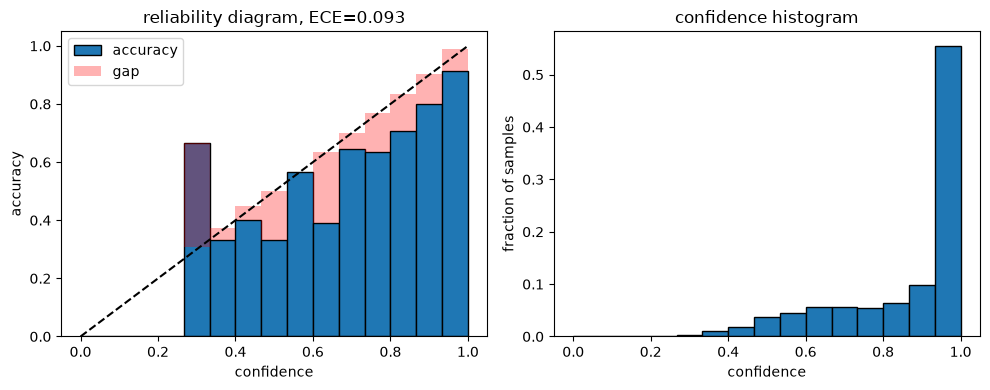

In [8]:
# Reliability diagram (given): bars = per-bin accuracy, red = gap to the diagonal.
M = 15
centers = (torch.arange(M) + 0.5) / M
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(centers, acc_b, width=1 / M, edgecolor="k", label="accuracy")
ax[0].bar(centers, conf_b - acc_b, bottom=acc_b, width=1 / M, color="r", alpha=0.3, label="gap")
ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set(xlabel="confidence", ylabel="accuracy", title=f"reliability diagram, ECE={ece(conf, correct):.3f}")
ax[0].legend()
ax[1].bar(centers, cnt_b / cnt_b.sum(), width=1 / M, edgecolor="k")
ax[1].set(xlabel="confidence", ylabel="fraction of samples", title="confidence histogram")
plt.tight_layout(); plt.show()

## 7. Brier score
Multiclass (Brier 1950): $\frac1N\sum_i\sum_c (p_{ic} - [y_i = c])^2$, range $[0, 2]$. The common **binary** form is
$\frac1N\sum_i (p_i - y_i)^2$ on the positive-class probability, range $[0,1]$. That is exactly half of the two-class
multiclass formula, and it is what scikit-learn returns for binary input. It is a proper scoring rule, so it rewards both calibration and sharpness.

In [9]:
def brier_multiclass(probs, y_true):
    onehot = F.one_hot(y_true, probs.shape[1]).to(probs.dtype)
    return ((probs - onehot) ** 2).sum(1).mean().item()


def brier_binary(p_pos, y01):
    return ((p_pos - y01.to(p_pos.dtype)) ** 2).mean().item()


check_close("Brier multiclass", brier_multiclass(probs, y_true), skm.brier_score_loss(y_true, probs.numpy(), labels=range(C)))
check_close("Brier binary", brier_binary(score3, yb_true), skm.brier_score_loss(yb_true, score3))
p2 = torch.stack([1 - score3, score3], 1)
check_close("binary Brier = half of 2-class multiclass Brier", brier_binary(score3, yb_true), brier_multiclass(p2, yb_true) / 2)

ok  Brier multiclass
ok  Brier binary
ok  binary Brier = half of 2-class multiclass Brier


### Reference: temperature scaling fixes most of the miscalibration (Guo et al. 2017, §4.2)
One scalar $T>0$ fitted on held-out NLL; $\text{softmax}(z/T)$ leaves the argmax, so accuracy is unchanged.
(In real use fit $T$ on a separate calibration split, not the split you report on.)

In [10]:
log_t = torch.zeros(1, requires_grad=True)
lbfgs = torch.optim.LBFGS([log_t], lr=0.1, max_iter=100)

def closure():
    lbfgs.zero_grad()
    loss = F.cross_entropy(logits / log_t.exp(), y_true)
    loss.backward()
    return loss

lbfgs.step(closure)
T = log_t.exp().item()
p_T = (logits / T).softmax(1)
print(f"T = {T:.2f}; ECE before {ece(conf, correct):.3f} -> after {ece(p_T.max(1).values, correct):.3f}; "
      f"Brier {brier_multiclass(probs, y_true):.3f} -> {brier_multiclass(p_T, y_true):.3f}")

T = 1.80; ECE before 0.093 -> after 0.056; Brier 0.335 -> 0.328


## Say it out loud
1. 1% positives: why is accuracy misleading? Which metrics would you report, and why PR-AUC over ROC-AUC there?
2. Micro vs macro vs weighted F1: which one hides poor performance on rare classes? What is micro-F1 for single-label multiclass?
3. Explain ROC-AUC as a probability. Why is it invariant to monotone transforms of the scores and to class balance?
4. Why compute AUC/F1 on the whole eval set rather than averaging per-batch values?
5. What does ECE measure, what are its weaknesses (binning, top-label only), and how would you fix a miscalibrated net?
6. What makes the Brier score / log-loss "proper", and why is ECE alone not a good training objective or model-selection metric?

<details><summary>Model answers</summary>

1. Predicting "always negative" scores 99% accuracy with zero recall. Report precision, recall and F1 at a chosen
   operating threshold, plus a threshold-free ranking metric. ROC-AUC is insensitive to class balance: FPR divides by the
   huge negative count, so many false positives barely move it. PR-AUC (AP) measures precision among the predicted
   positives, which is what matters when positives are rare. Its random baseline is the positive rate, so improvements are visible.
2. Micro pools TP/FP/FN, so frequent classes dominate it. Weighted averaging by support also hides rare classes. Macro weighs every
   class equally and exposes rare-class failures. For single-label multiclass every error is one FP (for the predicted class)
   and one FN (for the true class), so micro-P = micro-R = micro-F1 = accuracy (checked above).
3. AUC = P(score of a random positive > score of a random negative), ties counted ½ (Fawcett 2006; Hanley & McNeil 1982).
   It depends only on the ordering of scores, so any monotone transform leaves it unchanged. It is the normalized Mann–Whitney U.
   It conditions on the class (pairs are one positive, one negative), so it doesn't depend on the class ratio.
4. These are not means of per-example quantities: they are ratios or rank statistics over the whole set. A per-batch
   average weights batches equally (wrong for a short last batch) and, for AUC, ignores cross-batch pairs. Collect
   scores/labels over the full set, then compute once.
5. ECE is the expected gap |accuracy − confidence| over equal-width confidence bins (Naeini et al. 2015; Guo et al. 2017).
   Weaknesses: it depends on the number of bins, it has a bias that varies with sample size, it looks only at the top label, and a
   model can have ECE = 0 while being useless (always predict the base rate). Fixes: temperature scaling on a held-out
   set (one parameter, keeps accuracy), label smoothing or mixup during training, or ensembles. Reliability diagrams show the direction of the error
   (here: overconfident).
6. A proper scoring rule is minimized in expectation by reporting the true probabilities, so you cannot game it by
   hedging. Brier and log-loss are proper, and both mix calibration with sharpness/refinement. ECE is not proper: the
   "always predict the base rate" forecaster is perfectly calibrated and uninformative. So report ECE next to accuracy/NLL/Brier,
   never alone.
</details>

In [11]:
s.finish(lookups=0, score=None, notes="")

[P2.9] done in 0.1 min (within target 15 min)


0.12571560939153034